# 02 · Ratings over time

**Author:** Mohamed Elsadany · data collected from Google Play on 28 Oct 2026

**My question:** when did each app's ratings drop sharply, and what caused it?

I work from `data/processed/reviews_clean.csv` (created by `python src/cleaning.py`) and keep only reviews with
`in_full_coverage == True`, so every month I show has both Arabic and English reviews (see `01_cleaning.ipynb`,
section 5). The helper functions I wrote for this notebook are in `src/ratings.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ratings import monthly_stats, weekly_counts, find_surges, reviews_in, rising_words, version_stats  # noqa: E402

pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", message="obj.round has no effect")   # .round() on tables with date columns
IMAGES = ROOT / "images"

df = pd.read_csv(ROOT / "data" / "processed" / "reviews_clean.csv", parse_dates=["at", "coverage_start"])
df["content_clean"] = df["content_clean"].fillna("")
cov = df[df["in_full_coverage"]].copy()
print(f"{len(cov):,} of {len(df):,} reviews are inside each app's full-coverage period")

APPS = ["InstaPay", "Fawry", "Telda", "valU", "Vodafone Cash"]   # panel order in every chart
INK, MUTED, GRID = "#1f1e1c", "#6b6a64", "#e6e5e0"
BLUE, ORANGE = "#2a78d6", "#eb6834"

def style(ax):
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#b5b4ad")
    ax.tick_params(labelsize=8, colors=MUTED)

57,231 of 71,749 reviews are inside each app's full-coverage period


## 1. Ratings are split between 1 and 5 stars

Very few people leave 2, 3 or 4 stars: users either love the app or are angry at it.
Because of that, I use the **share of 1-star reviews** as my main measure of problems.

In [2]:
dist = pd.crosstab(cov["app"], cov["score"], normalize="index").mul(100).reindex(APPS)
dist.round(1).add_suffix("★")

score,1★,2★,3★,4★,5★
app,,,,,
InstaPay,30.1,2.7,3.1,3.8,60.3
Fawry,37.2,3.1,4.3,5.6,49.9
Telda,22.4,2.1,3.5,5.3,66.7
valU,48.4,2.8,2.6,3.0,43.2
Vodafone Cash,68.5,6.7,5.9,2.4,16.5


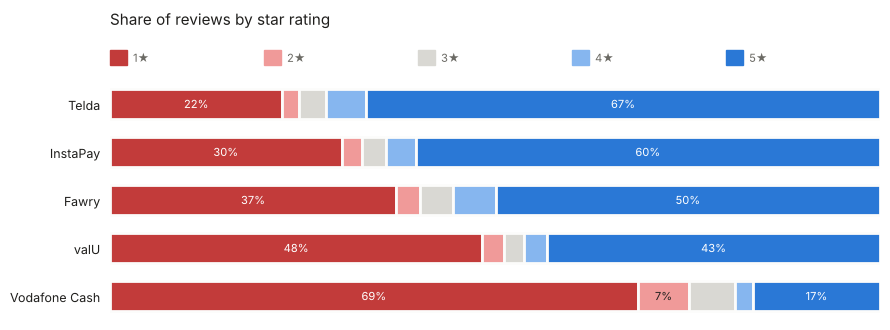

In [3]:
# One 100% bar per app: red = 1-2 stars, gray = 3, blue = 4-5, so the neutral middle separates bad from good.
STAR_COLORS = {1: "#c23b3a", 2: "#f09a99", 3: "#d9d8d3", 4: "#86b6ef", 5: "#2a78d6"}
order = dist.sort_values(1).index[::-1]      # most 1-star at the top

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, app in enumerate(order):
    left = 0
    for star in range(1, 6):
        w = dist.loc[app, star]
        ax.barh(i, w, left=left, color=STAR_COLORS[star], height=0.62, edgecolor="#fcfcfb", linewidth=2)
        if w >= 6:
            ax.text(left + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if star in (1, 5) else INK)
        left += w
ax.set_yticks(range(len(order)), order, fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_xticks([])
ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
ax.tick_params(left=False)
for star, x in zip(range(1, 6), [0, 20, 40, 60, 80]):
    ax.add_patch(plt.Rectangle((x, len(order) - 0.2), 2.2, 0.32, color=STAR_COLORS[star], clip_on=False))
    ax.text(x + 3, len(order) - 0.04, f"{star}★", fontsize=8, va="center", color=MUTED)
ax.set_ylim(-0.5, len(order) + 0.3)
ax.set_title("Share of reviews by star rating", loc="left", fontsize=11, color=INK, pad=12)
fig.tight_layout()
fig.savefig(IMAGES / "stars_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Written reviews are much harsher than the store rating

I compared my averages with the rating shown on each app's store page. The store rating counts everyone who tapped
a star, including people who wrote nothing, while people who take the time to write are more often unhappy.
So I read these reviews as a view of **problems**, not of overall satisfaction, and I keep that in mind when I quote averages.

The Vodafone Cash row compares wallet reviews with the rating of the whole **Ana Vodafone** app
(plans, bills, data and the wallet), so I don't compare its gap with the others.

In [4]:
meta = pd.read_csv(ROOT / "data" / "raw" / "apps_metadata.csv").set_index("app")
compare = pd.DataFrame({
    "store_rating": meta["score"].round(2),
    "store_ratings_count": meta["ratings"],
    "avg_of_written_reviews": cov.groupby("app")["score"].mean().round(2),
}).reindex(APPS)
compare["gap"] = (compare["avg_of_written_reviews"] - compare["store_rating"]).round(2)
compare

,store_rating,store_ratings_count,avg_of_written_reviews,gap
app,,,,
InstaPay,4.29,114730,3.62,-0.67
Fawry,3.85,178773,3.28,-0.57
Telda,4.75,102670,3.92,-0.83
valU,3.49,29443,2.90,-0.59
Vodafone Cash,4.38,2342682,1.92,-2.46


## 3. Monthly ratings

I plot two lines per app:
- **All reviews** (blue): every review in the month.
- **Reviews with 3+ words** (orange): leaves out "ممتاز" / "Good" style reviews. I noticed these arrive in waves
  when an app asks users to rate it (section 5), and they can lift the average while real complaints continue.

Each panel starts at that app's coverage start, so empty space means "Arabic reviews not collected yet",
not "no reviews".

In [5]:
monthly = monthly_stats(cov)
monthly["reliable"] = monthly["reviews"] >= 30          # too few reviews -> noisy average
monthly.pivot(index="month", columns="app", values="avg_stars").round(2).tail(12)

app,Fawry,InstaPay,Telda,Vodafone Cash,valU
month,,,,,
2025-11-01,2.78,3.61,4.26,NaN,2.73
2025-12-01,2.78,3.72,4.17,NaN,2.34
2026-01-01,3.29,3.76,4.00,NaN,2.81
2026-02-01,3.35,3.24,4.40,NaN,2.84
2026-03-01,3.33,3.38,4.20,NaN,3.08
2026-04-01,3.11,3.57,3.64,NaN,2.81
2026-05-01,2.96,3.49,3.70,2.15,2.21
2026-06-01,2.72,3.49,3.75,2.34,2.08
2026-07-01,2.43,3.46,3.51,1.83,1.50


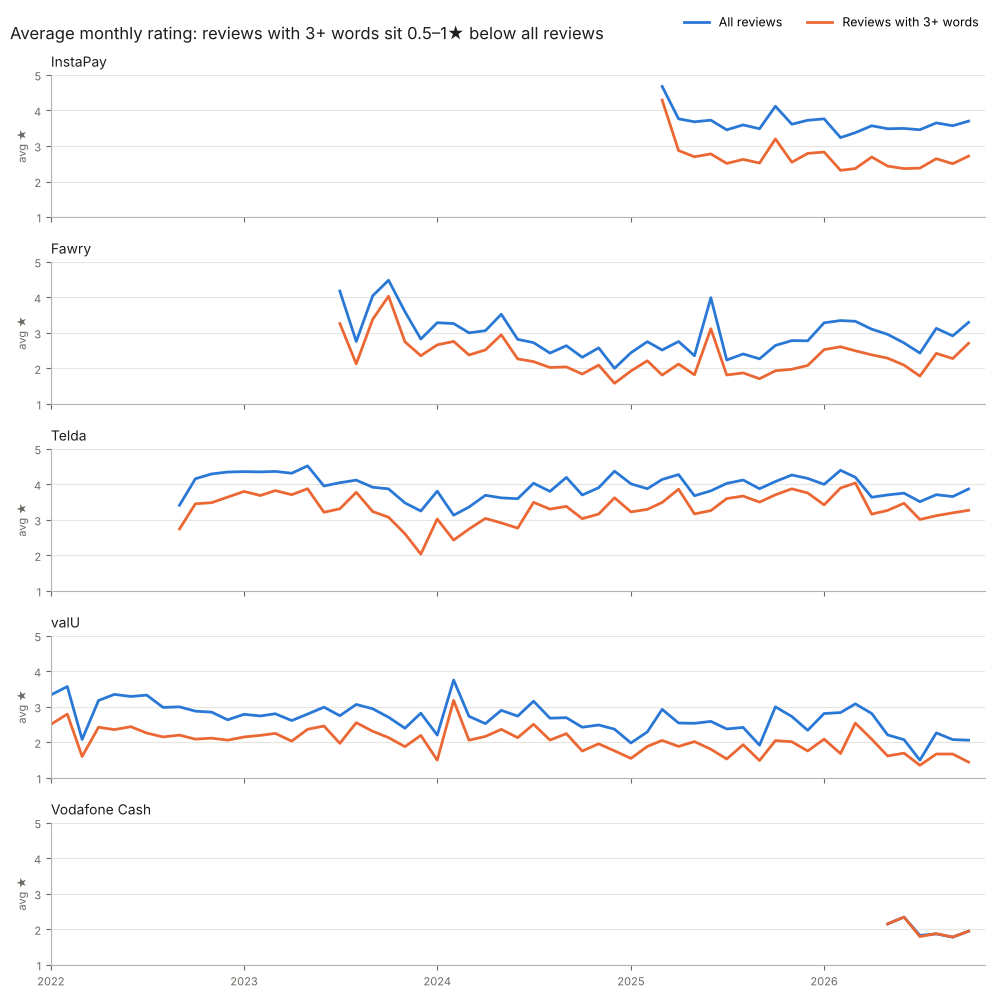

In [6]:
START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2026-11-01")
fig, axes = plt.subplots(len(APPS), 1, figsize=(10, 2.0 * len(APPS)), sharex=True)
for ax, app in zip(axes, APPS):
    m = monthly[(monthly["app"] == app) & monthly["reliable"] & (monthly["month"] >= START)]
    ax.plot(m["month"], m["avg_stars"], color=BLUE, lw=2, label="All reviews")
    ax.plot(m["month"], m["avg_stars_written"], color=ORANGE, lw=2, label="Reviews with 3+ words")
    ax.set_ylim(1, 5)
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_title(app, loc="left", fontsize=10, color=INK)
    ax.set_ylabel("avg ★", fontsize=8, color=MUTED)
    style(ax)
axes[-1].set_xlim(START, END)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Average monthly rating: reviews with 3+ words sit 0.5–1★ below all reviews", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(IMAGES / "monthly_rating.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Complaint surges

I define a **complaint surge** as a week where an app got at least 40 one-star reviews **and** at least 3x its usual
number (the median of the previous 8 weeks). I compare each app with its own recent past because the apps are very
different in size: InstaPay gets ~150 reviews a week, valU ~15.

My first version also flagged weeks that were simply busy, so I added one more rule: the week's average rating must be
below the app's normal average. Otherwise the extra 1-star reviews are just part of a general wave of new reviews
(for example Fawry in Oct 2023, which averaged 4.5★).

In [7]:
weekly = weekly_counts(cov)
usual_avg = cov.groupby("app")["score"].mean()
surges = find_surges(weekly, "one_star", min_count=40)
surges["app_usual_avg"] = surges["app"].map(usual_avg)
surges = surges[surges["avg_stars"] < surges["app_usual_avg"]].reset_index(drop=True)
surges[["app", "start", "end", "count", "usual_per_week", "peak_times_usual", "avg_stars"]].round(1)

,app,start,end,count,usual_per_week,peak_times_usual,avg_stars
0,Fawry,2024-12-16,2024-12-22,234,30.0,7.8,1.4
1,Fawry,2026-06-29,2026-07-05,150,35.5,4.2,2.3
2,InstaPay,2026-02-23,2026-03-08,1200,39.0,25.7,3.2
3,Telda,2022-10-17,2022-10-23,42,10.0,4.2,3.8
4,valU,2022-02-28,2022-03-13,495,14.0,28.3,1.9
5,valU,2024-03-11,2024-03-17,48,9.5,5.1,2.8


### What happened in each surge

For each surge I look at the app version most reviewers had, the words that rose most compared with the 90 days
before, and a few example reviews. I wrote the cause labels in the next table after reading these reviews.

In [8]:
details = []
for _, s in surges.iterrows():
    event = reviews_in(cov, s["app"], s["start"], s["end"], max_stars=2)
    before = reviews_in(cov, s["app"], s["start"] - pd.Timedelta(days=90), s["start"] - pd.Timedelta(days=1), max_stars=2)
    top_version = event["appVersion"].value_counts()
    print(f"\n=== {s['app']}  {s['start']:%d %b %Y} – {s['end']:%d %b %Y}  ({len(event)} reviews with 1–2★)")
    if len(top_version):
        print(f"Most common version: {top_version.index[0]} ({top_version.iloc[0] / top_version.sum():.0%} of reviews with a version)")
    words = rising_words(event, before, top=8)
    print("Rising words:", ", ".join(f"{w} {a:.0%} (was {b:.0%})" for w, a, b in words[["word", "share_in_event", "share_before"]].values))
    examples = event[event["word_count"] >= 8].sample(min(4, (event["word_count"] >= 8).sum()), random_state=1)
    for t in examples["content"]:
        print("  •", t[:180])
    details.append({"app": s["app"], "start": s["start"], "top_version": top_version.index[0] if len(top_version) else None})


=== Fawry  16 Dec 2024 – 22 Dec 2024  (240 reviews with 1–2★)
Most common version: 5.0.46 (98% of reviews with a version)
Rising words: عملاء 22% (was 17%), الكارت 11% (was 7%), الفلوس 14% (was 10%), مشاكل 5% (was 1%), الزفت 6% (was 3%), شركه 9% (was 6%), خدمه 35% (was 31%), تطبيق 14% (was 11%)
  • الكرت كان ممتاز فى الاول حاليا اصبح سئ جدا بسبب تعليق مبالغ السحب سواء من فودافون كاش او من مكن atM
  • خدمه العملا مش موجوده و مفيش حد بيتصرف في اي مشكله
  • خدمه عملاء سيئه محدش بيرد عليك ولا عارف تتواصل معاهم نهائى الفلوس مسمعتش فى الكارت بقالى يومين مش عارف اوصل لحل لان محدش بيرد عليا
  • تطبيق فاشل و الفلوس بتعلق و مش بتخرج من المكنه و حواراته كتير

=== Fawry  29 Jun 2026 – 05 Jul 2026  (158 reviews with 1–2★)
Most common version: 6.9.0 (62% of reviews with a version)
Rising words: التحديث 34% (was 9%), بعد 33% (was 12%), التطبيق 37% (was 21%), يفتح 17% (was 8%), المشكله 17% (was 9%), اخر 9% (was 3%), البرنامج 15% (was 8%), يعمل 10% (was 3%)
  • اكتر من اسبوع مش بيفتح رغم تم حذف وتنزيل

In [9]:
# My label for the cause of each surge, written after reading the reviews above.
CAUSES = {
    ("InstaPay", "2026-02-23"): "App stopped opening after the 1.12.0 update ('keeps stopping', 'this app has a bug', security check asking to remove apps not from Google Play)",
    ("Fawry", "2024-12-16"): "Fawry card: cash withdrawals stuck at ATMs (often Banque Misr) or from Vodafone Cash, and customer service not answering",
    ("Fawry", "2026-06-29"): "App crashing or not opening after the 6.9.0 update",
    ("valU", "2022-02-28"): "Backlash at a promotion: 'fake offers', hidden fees, applications rejected after hours of waiting",
    ("valU", "2024-03-11"): "8.0.x update broke the app; logins blocked when phone developer options are on (Error Code 8)",
    ("Telda", "2022-10-17"): "Sign-up failing with a false 'check your internet connection' error",
}
causes = surges[["app", "start", "end", "count", "peak_times_usual"]].copy()
causes["top_version"] = [d["top_version"] for d in details]
causes["cause"] = [CAUSES.get((a, f"{s:%Y-%m-%d}"), "not labeled yet") for a, s in zip(causes["app"], causes["start"])]
causes = causes.sort_values("count", ascending=False).reset_index(drop=True)
causes.rename(columns={"count": "one_star_reviews", "peak_times_usual": "x_usual"}).round(1)

,app,start,end,one_star_reviews,x_usual,top_version,cause
0,InstaPay,2026-02-23,2026-03-08,1200,25.7,1.12.0,"App stopped opening after the 1.12.0 update ('keeps stopping', 'this app has a bug', security check asking to remove..."
1,valU,2022-02-28,2022-03-13,495,28.3,6.0.3,"Backlash at a promotion: 'fake offers', hidden fees, applications rejected after hours of waiting"
2,Fawry,2024-12-16,2024-12-22,234,7.8,5.0.46,"Fawry card: cash withdrawals stuck at ATMs (often Banque Misr) or from Vodafone Cash, and customer service not answe..."
3,Fawry,2026-06-29,2026-07-05,150,4.2,6.9.0,App crashing or not opening after the 6.9.0 update
4,valU,2024-03-11,2024-03-17,48,5.1,8.0.3,8.0.x update broke the app; logins blocked when phone developer options are on (Error Code 8)
5,Telda,2022-10-17,2022-10-23,42,4.2,2.3.0,Sign-up failing with a false 'check your internet connection' error


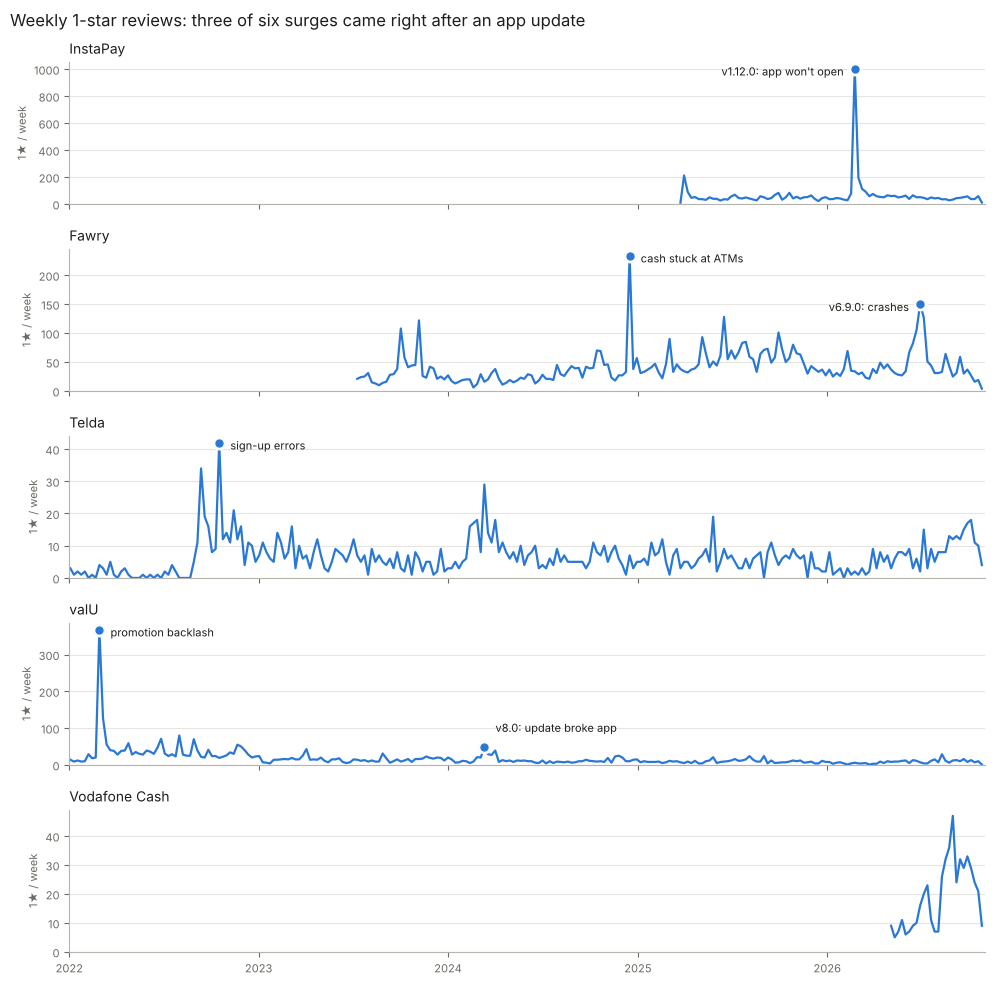

In [10]:
# Weekly 1-star reviews, with each surge I found labeled by its cause.
SHORT = {
    ("InstaPay", "2026-02-23"): "v1.12.0: app won't open",
    ("Fawry", "2024-12-16"): "cash stuck at ATMs",
    ("Fawry", "2026-06-29"): "v6.9.0: crashes",
    ("valU", "2022-02-28"): "promotion backlash",
    ("valU", "2024-03-11"): "v8.0: update broke app",
    ("Telda", "2022-10-17"): "sign-up errors",
}
fig, axes = plt.subplots(len(APPS), 1, figsize=(10, 2.0 * len(APPS)), sharex=True)
for ax, app in zip(axes, APPS):
    w = weekly[(weekly["app"] == app) & (weekly["week"] >= START)]
    ax.plot(w["week"], w["one_star"], color=BLUE, lw=1.6)
    for _, s in surges[surges["app"] == app].iterrows():
        if s["start"] < START:
            continue
        peak = w[(w["week"] >= s["start"]) & (w["week"] <= s["end"])]["one_star"].max()
        ax.plot(s["start"], peak, "o", ms=8, color=BLUE, mec="#fcfcfb", mew=2, zorder=3)
        right_side = s["start"] > pd.Timestamp("2025-09-01")
        low = peak < 0.3 * w["one_star"].max()          # small peak: lift the label above the line
        ax.annotate(SHORT.get((app, f"{s['start']:%Y-%m-%d}"), ""), (s["start"], peak),
                    xytext=(-8 if right_side else 8, 14 if low else -2), textcoords="offset points",
                    ha="right" if right_side else "left", va="center", fontsize=8, color=INK)
    ax.set_ylim(0, None)
    ax.set_title(app, loc="left", fontsize=10, color=INK)
    ax.set_ylabel("1★ / week", fontsize=8, color=MUTED)
    style(ax)
axes[-1].set_xlim(START, END)
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Weekly 1-star reviews: three of six surges came right after an app update", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(IMAGES / "complaint_surges.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Rating-prompt waves

While looking for surges I also found the opposite pattern: weeks with at least 3x the usual number of 5-star
reviews, mostly one or two words long. My best explanation is an in-app "rate us" prompt (likely, but not confirmed).
These waves lift the monthly average without saying anything about the product, which is why I also show the
3+ word line in section 3.

In [11]:
waves = find_surges(weekly, "five_star", min_count=100)
short_share = []
for _, s in waves.iterrows():
    r = reviews_in(cov, s["app"], s["start"], s["end"])
    five = r[r["score"] == 5]
    short_share.append((five["word_count"] <= 2).mean())
waves["five_star_with_1_2_words"] = (pd.Series(short_share) * 100).round(0).astype(int).astype(str) + "%"
waves[["app", "start", "end", "count", "usual_per_week", "peak_times_usual", "avg_stars", "five_star_with_1_2_words"]].round(1)

,app,start,end,count,usual_per_week,peak_times_usual,avg_stars,five_star_with_1_2_words
0,Fawry,2023-09-11,2023-10-15,2522,13.0,101.5,4.3,72%
1,Fawry,2025-06-16,2025-06-29,888,28.2,25.8,4.1,70%
2,Fawry,2026-02-09,2026-02-15,122,34.0,3.6,3.5,71%
3,Fawry,2026-06-08,2026-06-14,108,32.0,3.4,3.4,64%
4,InstaPay,2025-10-20,2025-10-26,600,83.5,7.2,4.4,76%
5,InstaPay,2026-02-23,2026-03-01,1213,96.5,12.6,3.2,67%
6,Telda,2022-10-17,2022-10-23,101,33.5,3.0,3.8,66%


One detail stood out: InstaPay's wave in the week of 23 Feb 2026 is the same week as its biggest complaint surge.
That week has **1,004 one-star and 1,213 five-star reviews**, so the monthly average (3.24★ in Feb 2026) hides how bad
the release was. The 1.12.0 version table below shows it more clearly.

## 6. Ratings by app version

I keep versions with at least 100 reviews, in release order. `change_vs_previous` is the change in average stars
from the previous version in the list, so big drops point to bad releases. Versions released during a rating-prompt
wave (for example Fawry 5.0.5) look better than they really were.

In [12]:
versions = version_stats(cov)
worst = versions.dropna(subset=["change_vs_previous"]).nsmallest(8, "change_vs_previous")
worst[["app", "appVersion", "first_seen", "reviews", "avg_stars", "one_star_share", "change_vs_previous"]].round(2)

,app,appVersion,first_seen,reviews,avg_stars,one_star_share,change_vs_previous
2,Fawry,5.0.3,2023-07-19 23:02:16,110,2.50,0.54,-1.77
17,Fawry,6.5.3,2025-07-07 00:52:47,388,2.18,0.65,-1.56
1,Fawry,5.0.20,2023-12-04 15:26:28,262,2.99,0.42,-1.34
38,InstaPay,1.9.4,2025-03-30 20:17:31,4431,3.72,0.27,-0.96
35,InstaPay,1.12.0,2026-02-21 06:11:22,5960,3.29,0.38,-0.95
44,Telda,2.39.6,2024-03-17 10:58:31,119,3.64,0.29,-0.82
30,Fawry,6.9.0,2026-06-11 19:43:12,319,2.10,0.65,-0.67
6,Fawry,5.0.34,2024-05-04 15:28:20,386,2.95,0.45,-0.60


In [13]:
versions[versions["app"] == "InstaPay"][["appVersion", "first_seen", "reviews", "avg_stars", "one_star_share", "change_vs_previous"]].round(2)

,appVersion,first_seen,reviews,avg_stars,one_star_share,change_vs_previous
36,1.9.0,2025-03-30 19:59:11,308,4.39,0.12,NaN
37,1.9.3,2025-03-30 19:59:12,681,4.68,0.05,0.29
38,1.9.4,2025-03-30 20:17:31,4431,3.72,0.27,-0.96
33,1.10.0,2025-10-13 09:51:03,1581,3.78,0.26,0.06
34,1.11.0,2025-12-23 11:51:03,1790,4.24,0.16,0.46
35,1.12.0,2026-02-21 06:11:22,5960,3.29,0.38,-0.95


## 7. Do the companies answer complaints?

Here I measure the reply rate on 1–2★ reviews and the median time each company takes to reply.

In [14]:
neg = cov[cov["is_negative"]]
replies = neg.groupby("app").agg(
    negative_reviews=("score", "size"),
    replied_pct=("has_reply", "mean"),
    median_reply_hours=("reply_hours", "median"),
).reindex(APPS)
replies["replied_pct"] = (replies["replied_pct"] * 100).round(1)
replies["median_reply_days"] = (replies["median_reply_hours"] / 24).round(1)
replies

,negative_reviews,replied_pct,median_reply_hours,median_reply_days
app,,,,
InstaPay,5782,73.4,72.7,3.0
Fawry,7785,98.6,4.8,0.2
Telda,2053,18.6,19.1,0.8
valU,5708,87.5,1106.5,46.1
Vodafone Cash,538,94.8,0.7,0.0


## What I found

*(All numbers are for each app's full-coverage period; see the tables above.)*

1. **Updates cause the worst weeks.** Three of the six complaint surges started right after an update that
   stopped the app from opening (InstaPay 1.12.0, Fawry 6.9.0, valU 8.0.x), and a fourth was a sign-up bug (Telda 2.3.0).
2. **InstaPay 1.12.0 (Feb 2026) is the biggest event in my data:** about 1,200 one-star reviews in two weeks,
   ~26x the usual level. That version averages about 1 star less than the version before it.
3. **Not every surge is technical.** Fawry's Dec 2024 surge is about money stuck in ATM withdrawals with the
   Fawry card and nobody answering, and valU's Feb 2022 surge is a reaction to a promotion and hidden fees.
4. **Rating-prompt waves inflate averages.** Fawry's Sep–Oct 2023 wave added ~2,500 five-star reviews,
   mostly one or two words, in five weeks.
5. **Reply speed varies a lot.** Fawry answers 99% of negative reviews (median 5 hours); valU answers 88%
   but takes a median of 46 days; Telda answers only 19%.
6. **Vodafone Cash is the most negative (about 69% one-star)**, but I only have 6 months of full coverage and
   ~700 reviews for it, so I compare it with care.

**Next:** in `03_complaint_topics.ipynb` I find out what users actually complain about, app by app.